# Labelling

In [1]:
import os
import librosa
import librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Audio, display, clear_output
import ipywidgets as widgets
from IPython.display import display
import time
import re

In [2]:
# use Metropolis when it needed
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager as font_manager

font_path = r"C:/Users/Acer/AppData/Local/Microsoft/Windows/Fonts/"

metropolis_fonts = {
    "regular": "Metropolis-Regular.otf",
    "bold": "Metropolis-Bold.otf",
    "semibold": "Metropolis-SemiBold.otf",
    "light": "Metropolis-Light.otf",
    "medium": "Metropolis-Medium.otf",
    "black": "Metropolis-Black.otf",
    "extrabold": "Metropolis-ExtraBold.otf",
    "italic": "Metropolis-RegularItalic.otf"
}

# dictionary for FontProperties
metro = {}

for style, filename in metropolis_fonts.items():
    fullpath = os.path.join(font_path, filename)
    if os.path.exists(fullpath):
        font_manager.fontManager.addfont(fullpath)
        metro[style] = FontProperties(fname=fullpath)
    else:
        print(f"⚠️ Not found {filename}")

# 0. Basic setup

In [5]:
# PATHS
ORG_AUDIO_DIR = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\data\org_audio_pb" # INPUT # real data used for cnn training
ORG_LABELS  = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\org_labels_test_pb.csv" # OUTPUT # We just run a test of 15 labels to show labelling process
FIX_LABELS  = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\fix_labels_test_pb.csv" # OUTPUT # test
SKIP_LABELS = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\skip_audio_test_pb.csv" # OUTPUT CONTROL # test
FIN_LABELS  = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\fin_labels_pb.csv" # OUTPUT # real

In [30]:
CLASS_NAMES = ["TM", "MH", "VO", "MU", "EM", "SO", "BI", "GE", "SI", "OT"]

In [31]:
# how many audio label we have to label

files = sorted([f for f in os.listdir(ORG_AUDIO_DIR) if f.endswith(".wav")])
total = len(files)

print(f"🎵 Audio segments found: {total}")

🎵 Audio segments found: 5130


In [ ]:
# MAIN CSV
if not os.path.exists(ORG_LABELS):
    ol = pd.DataFrame(columns=["filename"] + CLASS_NAMES)
    ol.to_csv(ORG_LABELS, index=False)
else:
    ol = pd.read_csv(ORG_LABELS)
    ol = ol[["filename"] + CLASS_NAMES]

# AUDIO SKIPPED CSV
if not os.path.exists(SKIP_LABELS):
    ol_skipped = pd.DataFrame(columns=["filename"])
    ol_skipped.to_csv(SKIP_LABELS, index=False)
else:
    ol_skipped = pd.read_csv(SKIP_LABELS)

In [33]:
# SPEC SETUP
SR_TARGET = 44100
N_MELS = 128
FMAX = 20000

### Functions

In [35]:
# show mel
def show_mel(audio, sr):
    mel = librosa.feature.melspectrogram(
        y=audio, sr=sr, n_mels=N_MELS, fmax=FMAX)
    mel_db = librosa.power_to_db(mel, ref=np.max)

    plt.figure(figsize=(10,4))
    librosa.display.specshow(
        mel_db, sr=sr, x_axis="time", y_axis="mel", fmax=FMAX)
    plt.title("Mel (0–20 kHz)")
    plt.colorbar(format="%+2.0f dB")
    plt.tight_layout()
    plt.show()

In [36]:
# load audio
def load_audio(idx, files):
    fname = files[idx]
    path = os.path.join(ORG_AUDIO_DIR, fname)
    audio, sr = librosa.load(path, sr=SR_TARGET)
    return fname, audio, sr

In [37]:
# plot
def plot_class_distribution(ol):

    if len(ol) == 0:
        print("There are not enough labels yet to generate a plot.")
        return

    # count labels per class
    labels_counts = ol[CLASS_NAMES].sum(axis=0).values.astype(int)

    counts_df = pd.DataFrame({
        "Class": CLASS_NAMES,
        "Count": labels_counts
    })

    plt.figure(figsize=(14, 5))
    bars = plt.bar(
        counts_df["Class"],
        counts_df["Count"],
        color="royalblue"
    )

    plt.ylim(0, counts_df["Count"].max() * 1.15)

    plt.title(
        "Number of labels per class",
        fontproperties=metro["bold"],
        fontsize=18
    )

    plt.xlabel(
        "Class",
        fontproperties=metro["regular"],
        fontsize=12
    )

    plt.ylabel(
        "Labels",
        fontproperties=metro["regular"],
        fontsize=12
    )

    plt.grid(axis="y", linestyle="--", alpha=0.5)

    # add counts above bars
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + (counts_df["Count"].max() * 0.02),
            str(int(height)),
            ha="center",
            va="bottom",
            fontproperties=metro["medium"],
            fontsize=11
        )

    # total labels annotation
    total_labels = counts_df["Count"].sum()
    plt.text(
        0.99, 0.95,
        f"Total labels = {total_labels}",
        transform=plt.gca().transAxes,
        ha="right",
        va="top",
        fontproperties=metro["light"],
        fontsize=12,
        bbox=dict(
            facecolor="white",
            edgecolor="gray",
            alpha=0.9
        )
    )

    plt.tight_layout()
    plt.show()

In [38]:
# labels validation
def parse_labels_from_text():
    allowed = set([lab.lower() for lab in CLASS_NAMES])

    while True:
        raw = input("Labels (e.g.: tm,vo,si), enter to skip or cancel to exit: ").lower().strip()

        if raw == "":
            return None  # skip
       
        if raw in ["cancel"]:
            return "CANCEL" # cancel

        parts = [p.strip() for p in raw.replace(",", " ").split() if p.strip()]
        invalid = [p for p in parts if p not in allowed]

        if invalid:
            print("\033[91m❌ Invalid label:", invalid, "\033[0m")
            print("   ✅ Valid options:", list(allowed))
            print("   🔁 Try again.\n")
            continue

        vect = {lab:0 for lab in CLASS_NAMES}
        for p in parts:
            vect[p.upper()] = 1
        return vect

In [39]:
# save labels
def save_labels(fname, vect):
    global ol

    row = {"filename": fname}
    for lab in CLASS_NAMES:
        row[lab] = vect[lab]

    if fname in ol["filename"].values:
        ol.loc[df["filename"] == fname, CLASS_NAMES] = [row[l] for l in CLASS_NAMES]
        print("♻️ Label updated.")
    else:
        ol = pd.concat([ol, pd.DataFrame([row])], ignore_index=True)
        print("✅ Label saved.")

    ol[CLASS_NAMES] = ol[CLASS_NAMES].astype(int)
    ol.to_csv(ORG_LABELS, index=False)

In [ ]:
# record skip audio
def skip_audio(fname):
    global ol_skipped
    if fname not in ol_skipped["filename"].values:
        ol_skipped = pd.concat([
            ol_skipped,
            pd.DataFrame([{"filename": fname}])
        ], ignore_index=True)
        ol_skipped.to_csv(SKIP_LABELS, index=False)
        print("↪ Audio skipped.")

In [41]:
# next audio
def get_next_audio_index():
    last_tag = -1
    last_skip = -1

    if len(ol) > 0:
        lf = ol["filename"].iloc[-1]
        if lf in files:
            last_tag = files.index(lf)

    if len(ol_skipped) > 0:
        ls = ol_skipped["filename"].iloc[-1]
        if ls in files:
            last_skip = files.index(ls)

    return max(last_tag, last_skip) + 1

# 1. Labelling workflow

📊 Dataset status after last labelled audio SEGMENT:


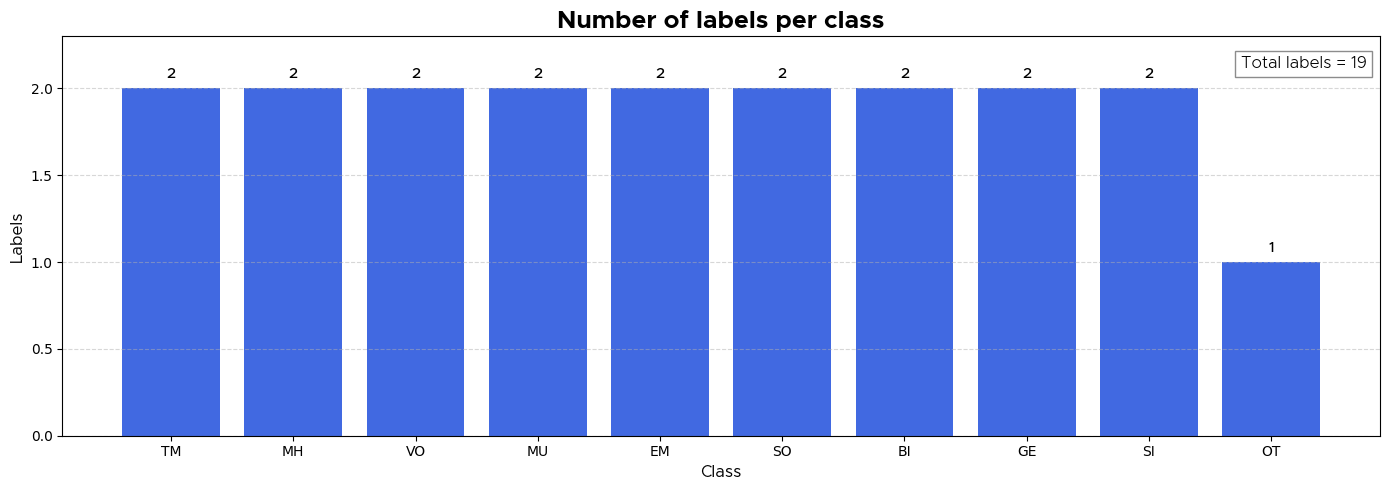


✅ Last audio segment checked: 20
➡️ Next recommended audio segment: 21 (001_34_P2.wav)

✅ Finished.


In [42]:
# Show automatic resume point
nx = get_next_audio_index()
if nx < total:
    print(f"✅ Resume from audio segment: {nx+1} ({files[nx]})")
else:
    print("✅ All audio files have been processed.")


while True:

    print("\n📌 Next audio suggested:", get_next_audio_index()+1)

    start = int(input("\nWhich audio segment should you start from? (ej: 1): ")) - 1
    end   = int(input("Up to which audio? (e.g.: 50): "))

    start = max(0, start)
    end   = min(end, total)

    last_done = None

    for idx in range(start, end):

        clear_output(wait=True)

        print("📊 Dataset status before labelling this audio segment:")
        plot_class_distribution(ol)

        fname, audio, sr = load_audio(idx, files)
        print(f"\n🎧 Audio segment {idx+1}/{total}: {fname}\n")
        
        audio_widget = Audio(audio, rate=sr, autoplay=False)
        display(audio_widget)

        import time
        time.sleep(0.05)
        
        show_mel(audio, sr)

        last_done = idx

        # if the audio segment is already labelled...
        if fname in ol["filename"].values:
            prev = ol[ol["filename"] == fname].iloc[0]
            print("\n⚠️ Already labelled:")
            for lab in CLASS_NAMES:
                print(f"  {lab}: {prev[lab]}")
            if input("\nReplace? (y/n): ").lower() != "y":
                continue

        print("\n📝 Valid labels: tm, mh, vo, mu, em, so, bi, ge, si")
        vect = parse_labels_from_text()

        if vect == "CANCEL":
            print("\n⛔ Cancelled. Nothing was saved or marked as skipped")
            break

        if vect is None:
            skip_audio(fname)
            continue

        save_labels(fname, vect)
        
        if idx == end - 1:
            clear_output(wait=True)
            print("📊 Dataset status after last labelled audio SEGMENT:")
            plot_class_distribution(ol)


    # show real advance
    nx = get_next_audio_index()
    print(f"\n✅ Last audio segment checked: {last_done+1}")
    if nx < total:
        print(f"➡️ Next recommended audio segment: {nx+1} ({files[nx]})")
    else:
        print("✅ All audio segments processed.")

    if input("\nWould you label another range? (y/n): ").lower() != "y":
        print("\n✅ Finished.")
        break

# 2. Checks

In [ ]:
# LABELS PATH
# using our real final labels only here to show how we verified
# labelling for exact 27 audio segments per point and period in the study area (Venice)

ORG_LABELS = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\org_labels_pb.csv" 
ol = pd.read_csv(ORG_LABELS)

### Functions

In [51]:
# function to extract points
def get_sampling_point(filename):
    match = re.match(r"(\d{3})", str(filename))
    return match.group(1) if match else None

# function to extract periods
def get_period(filename):
    match = re.search(r"(P1|P2)", str(filename))
    return match.group(1) if match else None

In [57]:
# the total label count is computed at the multi-hot vector level,
# counting each complete annotation for each audio segment as single label instance
# 5130 audio segments, then 5130 labels expected

total_labels = (ol[CLASS_NAMES].sum(axis=1) > 0).sum()
total_labels

np.int64(5130)

In [58]:
# add points and period colums to our dataframe
ol["sampling_point"] = ol["filename"].apply(get_sampling_point)
ol["period"] = ol["filename"].apply(get_period)

# counts per point and period
counts = ol.groupby(["sampling_point", "period"]).size().unstack(fill_value=0)

# assuere numeric order by point
counts = counts.sort_index()

print("\n✅ Count per point and period:")
print(counts)


✅ Count per point and period:
period          P1  P2
sampling_point        
001             27  27
002             27  27
003             27  27
004             27  27
005             27  27
...             ..  ..
098             27  27
099             27  27
100             27  27
101             27  27
102             27  27

[95 rows x 2 columns]


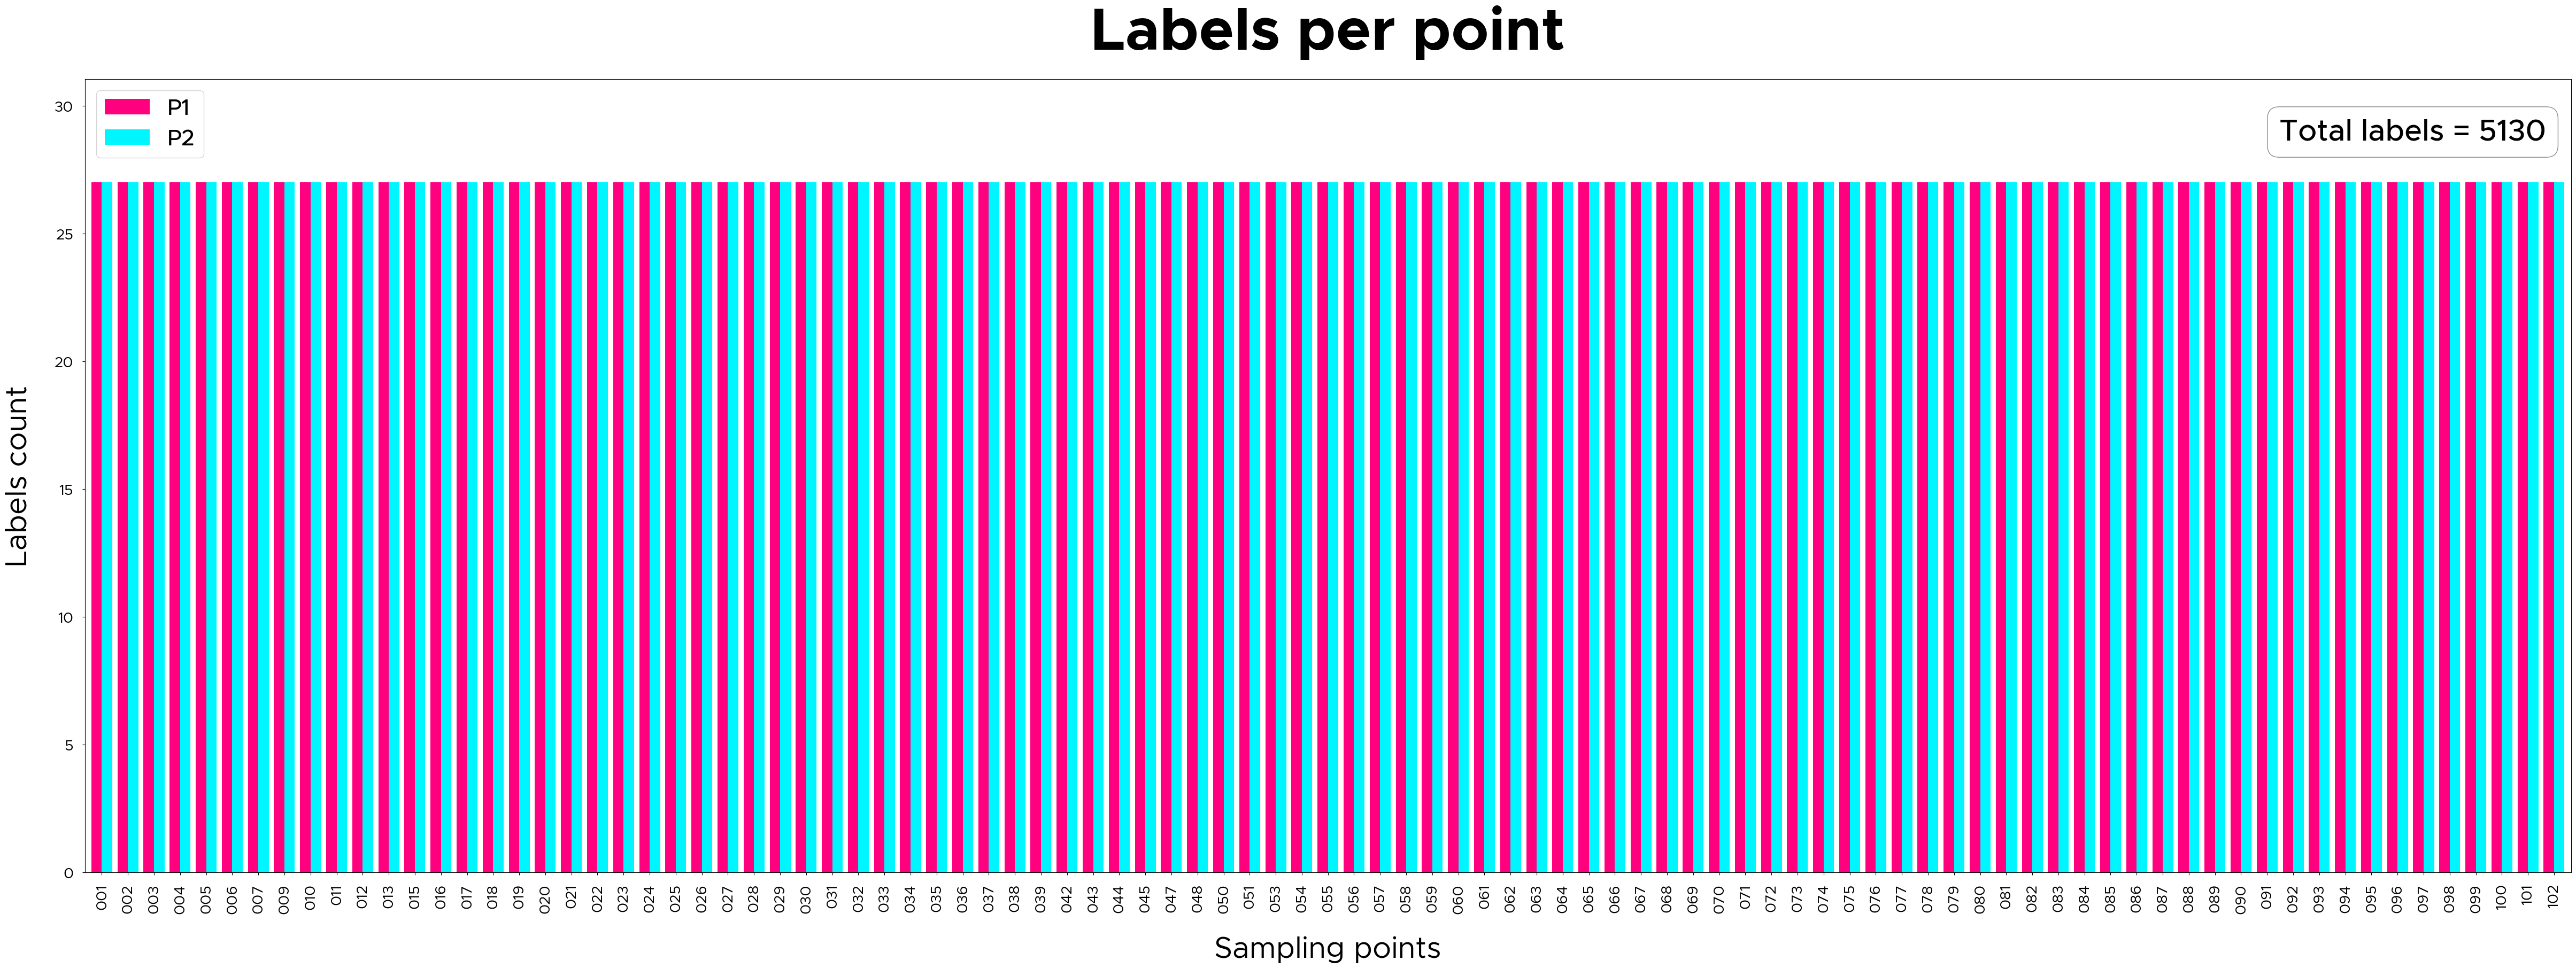

In [59]:
# plot

ax = counts.plot(
    kind="bar",
    figsize=(60, 28),
    width=0.8,
    color=["#ff007f", "#00f6ff"]
)

ax.set_title(
    "Labels per point",
    pad=40,
    fontproperties=FontProperties(
        fname=metro["bold"].get_file(),
        size=80
    )
)

ax.set_xlabel(
    "Sampling points",
    labelpad=30,
    fontproperties=FontProperties(
        fname=metro["regular"].get_file(),
        size=40
    )
)

ax.set_ylabel(
    "Labels count",
    labelpad=30,
    fontproperties=FontProperties(
        fname=metro["regular"].get_file(),
        size=40
    )
)

ax.tick_params(axis="x", rotation=90, pad=12)
ax.tick_params(axis="y", pad=12)

for t in ax.get_xticklabels():
    t.set_fontproperties(
        FontProperties(fname=metro["regular"].get_file(), size=20)
    )

for t in ax.get_yticklabels():
    t.set_fontproperties(
        FontProperties(fname=metro["regular"].get_file(), size=20)
    )

ax.legend(
    prop=FontProperties(
        fname=metro["medium"].get_file(),
        size=30
    )
)

ax.text(.99,
    0.95,
    f"Total labels = {int(total_labels)}",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontproperties=FontProperties(
        fname=metro["medium"].get_file(),
        size=40
    ),
    bbox=dict(
        facecolor="white",
        edgecolor="gray",
        alpha=0.9,
        boxstyle="round,pad=0.4"
    )
)

ax.margins(y=0.15)

plt.subplots_adjust(top=0.78, bottom=0.25)
plt.show()

# 3. Rectifier

In [68]:
ORG_LABELS  = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\org_labels_test_pb.csv" # define again the 15 test labels path
ol = pd.read_csv(ORG_LABELS)

📊 Dataset status after last labelled audio SEGMENT:


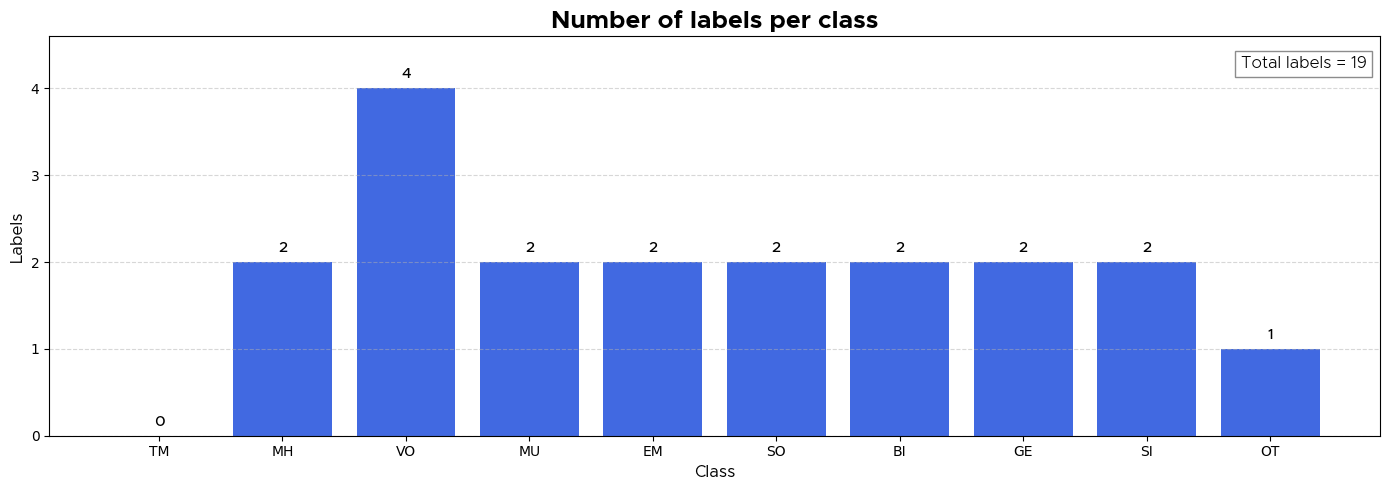


✅ Rectification completed.
✅ New CSV saved at:
C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\fix_labels_test_pb.csv
✅ Last rectified audio: 2 of 2
✅ You can continue later from index 3


In [73]:
# CHOOSE CLASS TO RECTIFY

print("\nAvailable classes:", CLASS_NAMES)
target_class = input("\n>>> Which class do you want to review/rectify? (e.g., GE): ").strip().upper()

if target_class not in CLASS_NAMES:
    raise ValueError("❌ Invalid class.")

print(f"\n✅ Filtering audios where {target_class} = 1...\n")

ol_filtered = ol[ol[target_class] == 1].reset_index(drop=True)
review_files = ol_filtered["filename"].tolist()

total_rectified = len(review_files)

print(f"✅ Total audios marked as {target_class}: {total_rectified}")
print("✅ ONLY these audios will be reviewed.\n")


# AUTOMATIC RESUME

RECTIF_CSV = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\rectif.csv"

if not os.path.exists(RECTIF_CSV):
    pd.DataFrame(columns=["class","last_index"]).to_csv(RECTIF_CSV, index=False)

ol_prog = pd.read_csv(RECTIF_CSV)

if target_class in ol_prog["class"].values:
    last_done_global = int(ol_prog[ol_prog["class"] == target_class]["last_index"].iloc[0])
else:
    last_done_global = -1

print(f"✅ Last audio previously rectified for {target_class}: {last_done_global+1}/{total_rectified}")

auto_start = last_done_global + 1


# RANGES

print("\n📌 Automatic suggestion:", auto_start+1)

user_start = input(f"Which index to start from? (ENTER for {auto_start+1}): ").strip()
start = int(user_start)-1 if user_start else auto_start
start = max(0, start)

user_end = int(input("Up to which index? (e.g., 200): "))
end = min(user_end, total_rectified)


# MAIN RECTIFICATION LOOP

for idx in range(start, end):

    fname = review_files[idx]

    clear_output(wait=True)
    print("📊 Current dataset status:")
    plot_class_distribution(ol)

    print(f"\n🎧 Rectifying {idx+1}/{total_rectified} — {fname}\n")

    # load audio file
    audio_path = os.path.join(ORG_AUDIO_DIR, fname)
    audio, sr = librosa.load(audio_path, sr=SR_TARGET)

    display(Audio(audio, rate=sr))
    show_mel(audio, sr)

    # show current labels
    prev = ol[ol["filename"] == fname].iloc[0]
    print("\n⚠️ Current labels:")
    for lab in CLASS_NAMES:
        print(f"  {lab}: {prev[lab]}")

    # confirmation step
    ans = input("\nReplace labels? (y/n/cancel): ").strip().lower()

    if ans == "cancel":
        break
    if ans != "y":
        continue

    # request new labels
    print("\n📝 Valid labels: tm, mh, vo, mu, em, so, bi, ge, si, ot")
    print("🛑 Type 'cancel' to stop rectification and save progress.\n")

    vect = parse_labels_from_text()

    # global cancel: exit rectification loop immediately
    if vect == "CANCEL":
        break

    # skip audio (ENTER)
    if vect is None:
        skip_audio(fname)
        continue

    # apply rectified labels to the in-memory dataframe
    ol.loc[ol["filename"] == fname, CLASS_NAMES] = [
        vect[lab] for lab in CLASS_NAMES
    ]

    # save progress
    ol_prog = pd.read_csv(RECTIF_CSV)

    if target_class in ol_prog["class"].values:
        ol_prog.loc[ol_prog["class"] == target_class, "last_index"] = idx
    else:
        ol_prog = pd.concat([
            ol_prog,
            pd.DataFrame([{"class": target_class, "last_index": idx}])
        ], ignore_index=True)

    if idx == end - 1:
        clear_output(wait=True)
        print("📊 Dataset status after last labelled audio SEGMENT:")
        plot_class_distribution(ol)

    ol_prog.to_csv(RECTIF_CSV, index=False)


# SAVE FINAL FIXED CSV

ol.to_csv(FIX_LABELS, index=False)

print("\n✅ Rectification completed.")
print(f"✅ New CSV saved at:\n{FIX_LABELS}")
print(f"✅ Last rectified audio: {idx+1} of {total_rectified}")
print(f"✅ You can continue later from index {idx+2}")


In [74]:
# LOAD ORIGINAL AND RECTIFIED LABELS

df_orig = pd.read_csv(ORG_LABELS)
df_fixed = pd.read_csv(FIX_LABELS)

print("✅ Original CSV:", df_orig.shape)
print("✅ Rectified CSV:", df_fixed.shape)

✅ Original CSV: (19, 11)
✅ Rectified CSV: (19, 11)


In [75]:
# LABEL COUNTS PER CLASS (ORG)

counts_orig = df_orig[CLASS_NAMES].sum()
counts_orig


TM    2
MH    2
VO    2
MU    2
EM    2
SO    2
BI    2
GE    2
SI    2
OT    1
dtype: int64

In [76]:
# LABEL COUNTS PER CLASS (FIXED)

counts_fixed = df_fixed[CLASS_NAMES].sum()
counts_fixed

TM    0
MH    2
VO    4
MU    2
EM    2
SO    2
BI    2
GE    2
SI    2
OT    1
dtype: int64

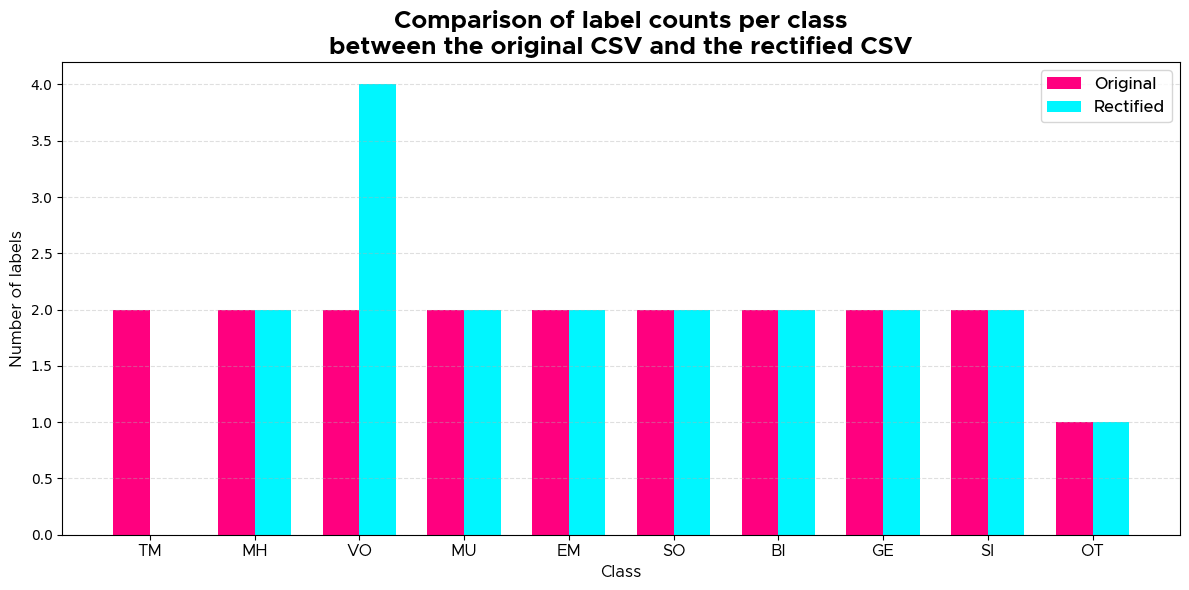

In [77]:
# COMPARATIVE PLOT

x = np.arange(len(CLASS_NAMES))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    counts_orig.values,
    width,
    label="Original",
    color="#ff007f"
)

plt.bar(
    x + width / 2,
    counts_fixed.values,
    width,
    label="Rectified",
    color="#00f6ff"
)

plt.xticks(
    x,
    CLASS_NAMES,
    fontproperties=FontProperties(
        fname=metro["regular"].get_file(),
        size=12
    )
)

plt.ylabel(
    "Number of labels",
    fontproperties=FontProperties(
        fname=metro["regular"].get_file(),
        size=12
    )
)

plt.xlabel(
    "Class",
    fontproperties=FontProperties(
        fname=metro["regular"].get_file(),
        size=12
    )
)

plt.title(
    "Comparison of label counts per class\nbetween the original CSV and the rectified CSV",
    fontproperties=FontProperties(
        fname=metro["bold"].get_file(),
        size=18
    )
)

plt.legend(
    prop=FontProperties(
        fname=metro["medium"].get_file(),
        size=12
    )
)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


# Delete OT

In [3]:
FIX_LABELS  = r"C:\Users\Acer\Desktop\TSI\U_VNE_CNN\0_labelling-py-R\results\fix_labels_pb.csv" # real fixed labels
df_fixed = pd.read_csv(FIX_LABELS)

In [6]:
# remove rows where OT == 1
df_final = df_fixed[df_fixed["OT"] != 1]

# drop OT column
df_final = df_final.drop(columns=["OT"])

# save final csv
df_final.to_csv(FIN_LABELS, index=False)

print("Rows before:", len(df_fixed))
print("Rows after:", len(df_final))
print("Columns:", df_final.columns.tolist())

Rows before: 5130
Rows after: 5115
Columns: ['filename', 'TM', 'MH', 'VO', 'MU', 'EM', 'SO', 'BI', 'GE', 'SI']
